# Overview

A common numerical solution to the heat equation is discretization: breaking time into chunks and updating the position vector using an update equation, which in this case is linear and so we can do this as a linear transformation (i.e. matrix multiplication) on our vector. Today we'll explore some different methods using `numpy` and `jax` to implement this tranformation and compare their performance.

Start by running the code cell below to import the necessary packages. You'll notice that the last line is importing the update functions I wrote in a separate `heat_equation.py` file.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import jax
import jax.numpy as jnp
from jax.experimental import sparse
from inspect import getsource
from heat_equation import advance_time_matvecmul, get_A, get_sparse_A, advance_time_numpy, advance_time_jax, run, plot

## Initial Condition

We're modeling heat diffusion in 2D, so our position vector `u` has shape (N, 2) (in other words, `u` is an NxN matrix). The function `get_A(N)` makes an $N^{2}$x$N^{2}$ matrix `A` which will be the matrix of the linear transformation of updating the heat's diffusion throughout `u`. The next code cell gets `A`, initializes `u`, and initializes our other parameter, `epsilon` (step size, essentially). Here is the function get_A(N):

In [2]:
print(getsource(get_A))

def get_A(N):
    n = N * N
    diagonals = [-4 * np.ones(n), np.ones(n-1), np.ones(n-1), np.ones(n-N), np.ones(n-N)]
    diagonals[1][(N-1)::N] = 0
    diagonals[2][(N-1)::N] = 0
    A = np.diag(diagonals[0]) + np.diag(diagonals[1], 1) + np.diag(diagonals[2], -1) + np.diag(diagonals[3], N) + np.diag(diagonals[4], -N)
    return A



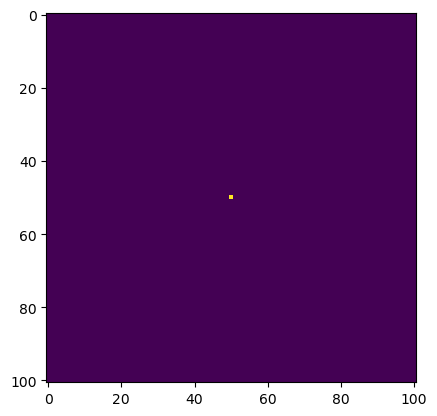

In [3]:
N = 101
epsilon = 0.2
A = get_A(N)
# construct initial condition: 1 unit of heat at midpoint. 
u0 = np.zeros((N, N))
u0[int(N/2), int(N/2)] = 1.0
plt.imshow(u0)

## Method 1: `numpy` Matrix Multiplication

This function multiplies `u` by the update matrix `A`, using numpy to flatten `u` and multiply component-wise. We'll run it for 2700 iterations, visualizing every 300, and time it (not including the plotting time).

In [4]:
print(getsource(advance_time_matvecmul))

def advance_time_matvecmul(A, u, epsilon):
    """Advances the simulation by one timestep, via matrix-vector multiplication
    Args:
        A: The 2d finite difference matrix, N^2 x N^2. 
        u: N x N grid state at timestep k.
        epsilon: stability constant.

    Returns:
        N x N Grid state at timestep k+1.
    """
    N = u.shape[0]
    u = u + epsilon * (A @ u.flatten()).reshape((N, N))
    return u



In [5]:
%%time
u = u0
plots = []
for i in range(9):
    for j in range(300):
        u = advance_time_matvecmul(A, u, epsilon)
    plots.append(u)

CPU times: total: 7min
Wall time: 2min 8s


In [6]:
print(getsource(plot))

def plot(plots):
    """takes a list of nine plots and plots them out, returns fig"""
    fig, ax = plt.subplots(3, 3)
    for i in range(9):
        ax.flatten()[i].imshow(plots[i])



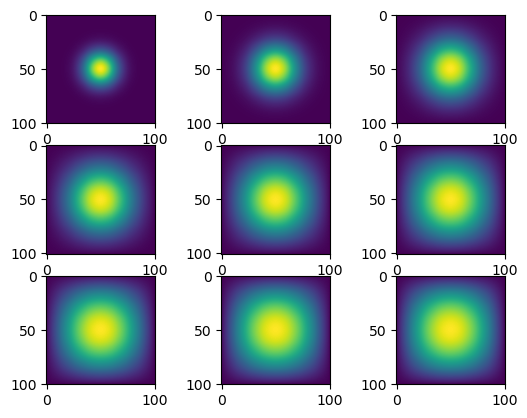

In [7]:
plot(plots)

It's very slow! Don't worry, our next method will improve the time by using JIT (just-in-time) compilation and `jax`'s built-in sparse matrix structure.

## Sparse Matrix Multiplication

This time we'll make a new function `get_sparse_A(N)` to make a sparse version of `A`. Then we'll use `jax.jit` to compile the same function `advance_time_matvecmul` using JIT compilation. Then we'll run it 2700 times, plotting every 300 iterations, and time it, just like before.

In [8]:
print(getsource(get_sparse_A))

def get_sparse_A(N):
    A = get_A(N)
    A_jnp = jnp.asarray(A)
    A_sp_matrix = sparse.BCOO.fromdense(A_jnp)
    return A_sp_matrix



In [9]:
jitted_matvecmul = jax.jit(advance_time_matvecmul)

In [10]:
%%time
u = jnp.asarray(u0)
A_sp_matrix = get_sparse_A(N)
plots = []
for i in range(9):
    for j in range(300):
        u = jitted_matvecmul(A_sp_matrix, u, epsilon)
    plots.append(u)

CPU times: total: 42.8 s
Wall time: 33.8 s


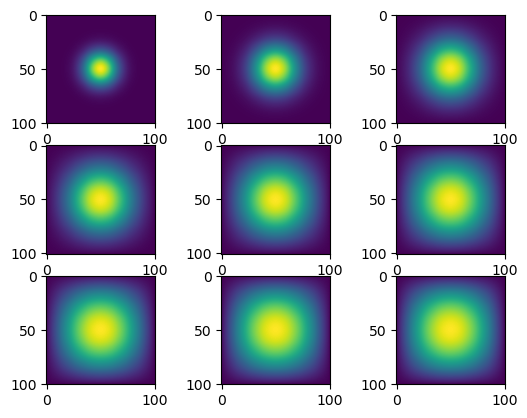

In [11]:
plot(plots)

That was a bit better! But maybe there's an even better way to do it by bypassing the matrix multiplication altogether...

## Direct Operation with `numpy`

We all know that vectorized `numpy` functions are very fast and efficient. In this case, we can actually use the `numpy` method `np.roll` to "spread" out the heat. This should be much faster than making a huge matrix `A`, even if `A` is sparse!

In [12]:
print(getsource(advance_time_numpy))

def advance_time_numpy(u, epsilon):
    N = u.shape[0]
    temp = np.zeros((N+2, N+2))
    temp[1:N+1, 1:N+1] = temp[1:N+1, 1:N+1] + u
    temp = temp*0.2
    temp = temp + np.roll(temp, 1, axis = 0) + np.roll(temp, -1, axis = 0) + np.roll(temp, 1, axis = 1) + np.roll(temp, -1, axis = 1)
    return temp[1:N+1, 1:N+1]



In [13]:
print(getsource(run))

def run(f, u0, epsilon):
    """ runs the function f 2700 times, making a plot every 300 iterations
    returns a list of 9 plots: one for every 300 iterations."""
    
    u = u0
    plots = []
    for i in range(9):
        for j in range(300):
            u = f(u, epsilon)
        plots.append(u)
        
    return plots



In [14]:
%%time
plots = run(advance_time_numpy, u0, epsilon)

CPU times: total: 484 ms
Wall time: 512 ms


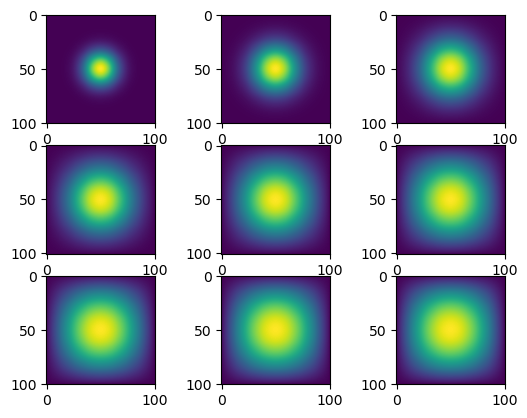

In [15]:
plot(plots)

WOW -- so much better! Let's try to use `jax` to speed this up even more.

## Direct Operation with `jax`

This function does the same thing as the `numpy` version, but using `jnp` arrays. This means we have to make new arrays each time we want to change a value, because `jnp` arrays are immutable.

In [16]:
print(getsource(advance_time_jax))

@jax.jit
def advance_time_jax(u, epsilon):
    N = u.shape[0]
    temp = jnp.zeros((N+2, N+2))
    temp2 = temp.at[1:N+1, 1:N+1].set(temp[1:N+1, 1:N+1] + u)
    temp3 = temp2*0.2
    temp4 = temp3 + jnp.roll(temp3, 1, axis = 0) + jnp.roll(temp3, -1, axis = 0) + jnp.roll(temp3, 1, axis = 1) + jnp.roll(temp3, -1, axis = 1)
    return temp4[1:N+1, 1:N+1]



In [17]:
# warming up the function (getting it compiled to speed it up)
u = u0
for j in range(3):
    u = np.array(advance_time_jax(jnp.asarray(u), epsilon))

In [18]:
%%time
plots = run(advance_time_jax, u0, epsilon)

CPU times: total: 219 ms
Wall time: 93.8 ms


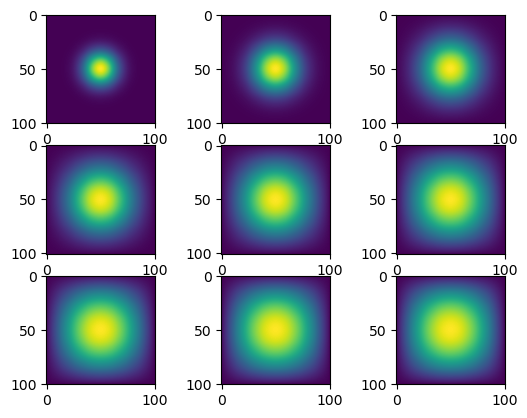

In [19]:
plot(plots)

# Comparing the Methods

All four methods got the correct heat diffusion diagrams. But each one was faster than the last. The direct operation was faster than matrix multiplication, but this approach might not work for every system of differential equations. 